# 03 – Explainability: why does the model give this score?

This notebook explains the saved HealthLens model (`ml/models/model.joblib`) using **SHAP** (which factors push a score up or down) and **counterfactuals** (what would need to change to fall below the screening threshold).

Run `python ml/src/train.py` first so the model files exist.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

ROOT = Path.cwd()
while not (ROOT / 'ml').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'ml' / 'src'))

import matplotlib.pyplot as plt
import pandas as pd
from explain import HealthLensExplainer

ex = HealthLensExplainer()
print('Explaining:', ex.card['model'], ex.card['feature_set'], '| unit:', ex.unit)
print('Screening threshold:', round(ex.threshold, 3))

Background dataset has 614 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=614 when initializing the masker.


Explaining: logreg baseline | unit: log-odds
Screening threshold: 0.284


## 1. Global view: which factors matter most overall?
Average size of each factor's impact across the training patients. Glucose should dominate (clinically sensible). Features the model dropped (RFE) are listed separately.

,feature,label,mean_abs_impact,share
0,Glucose,Glucose,0.441,0.365
1,BMI,BMI,0.276,0.229
2,Pregnancies,Number of pregnancies,0.157,0.130
3,Age,Age,0.149,0.124
4,DiabetesPedigreeFunction,Family history score,0.112,0.093
5,Insulin,Insulin,0.071,0.059


Not used by the model: ['BloodPressure', 'SkinThickness']


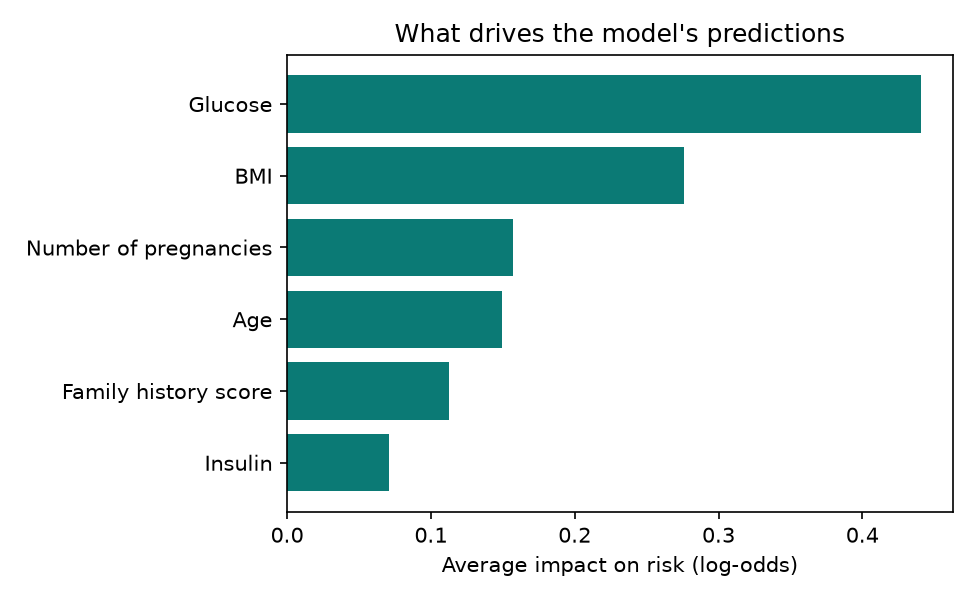

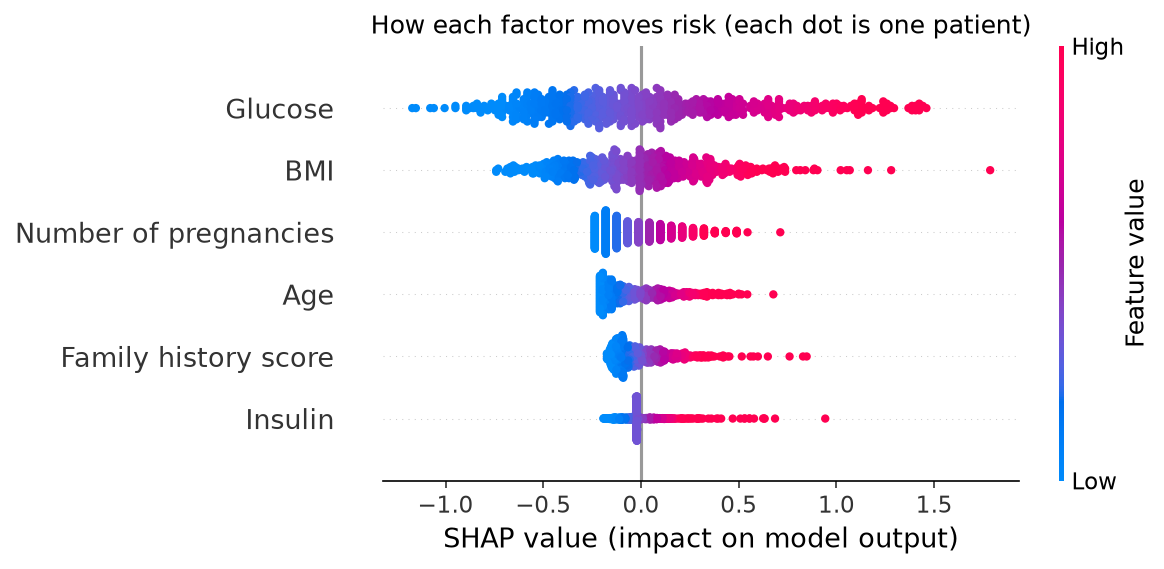

In [2]:
imp, values = ex.global_importance()
display(imp.round(3))
print('Not used by the model:', ex.not_used_features)
ex.save_global_plots()
from IPython.display import Image
display(Image(str(ROOT / 'ml' / 'reports' / 'shap_global_importance.png')))
display(Image(str(ROOT / 'ml' / 'reports' / 'shap_summary.png')))

## 2. One patient at a time
A lower-risk patient (the sample from `predict.py`) and a higher-risk one. Bars to the right raise the score; bars to the left lower it. A factor marked *not measured* was filled with a typical value, so treat it with care.

In [3]:
low = dict(Pregnancies=1, Glucose=118, BloodPressure=76, SkinThickness=25, Insulin=0, BMI=24.8, DiabetesPedigreeFunction=0.35, Age=24)
high = dict(Pregnancies=6, Glucose=170, BloodPressure=80, SkinThickness=35, Insulin=200, BMI=36, DiabetesPedigreeFunction=0.9, Age=50)

def show(rec, title):
    r = ex.explain_one(rec)
    f = pd.DataFrame(r['factors'])
    colors = ['#d9534f' if v > 0 else '#2e8b57' for v in f['impact']]
    plt.figure(figsize=(6.5, 3.5))
    plt.barh(f['label'][::-1], f['impact'][::-1], color=colors[::-1])
    plt.axvline(0, color='k', lw=0.8)
    plt.xlabel('Impact on score (log-odds)')
    plt.title(f"{title}: p={r['probability']:.2f}, flagged={r['flagged_higher_risk']}")
    plt.tight_layout(); plt.show()
    return r

r_low = show(low, 'Lower-risk patient')
r_high = show(high, 'Higher-risk patient')
display(pd.DataFrame(r_high['factors'])[['label','value_used','was_missing','impact','direction','share']])

,label,value_used,was_missing,impact,direction,share
0,Glucose,170.0,False,0.9267,raises risk,0.5402
1,Age,50.0,False,0.2188,raises risk,0.1275
2,Family history score,0.9,False,0.1968,raises risk,0.1147
3,BMI,36.0,False,0.1791,raises risk,0.1044
4,Number of pregnancies,6.0,False,0.0988,raises risk,0.0576
5,Insulin,200.0,False,0.0955,raises risk,0.0557


## 3. What-if: change one value, see the new score

In [4]:
print(ex.what_if(high, {'Glucose': 110}))
print(ex.what_if(high, {'Glucose': 110, 'BMI': 28}))

{'changes': {'Glucose': 110}, 'before': 0.9119153308410235, 'after': 0.5715426760680392, 'threshold': 0.2844569025400903, 'flagged_before': True, 'flagged_after': True}
{'changes': {'Glucose': 110, 'BMI': 28}, 'before': 0.9119153308410235, 'after': 0.38238441969071363, 'threshold': 0.2844569025400903, 'flagged_before': True, 'flagged_after': True}


## 4. Counterfactuals: smallest changes that bring a flagged patient under the threshold
Only Glucose and BMI are varied (never age, pregnancies or family history), and every option is re-checked with the real model. These are illustrations of the model's behaviour, **not medical advice**.

In [5]:
cf = ex.counterfactuals(high, n=3)
for o in cf['options']:
    print(o)

100%|██████████| 1/1 [00:00<00:00,  6.88it/s]

{'changes': [{'feature': 'Glucose', 'label': 'Glucose', 'from': 170.0, 'to': 72.0}], 'new_probability': 0.2670550622688316}
{'changes': [{'feature': 'Glucose', 'label': 'Glucose', 'from': 170.0, 'to': 88.0}, {'feature': 'BMI', 'label': 'BMI', 'from': 36.0, 'to': 28.0}], 'new_probability': 0.22604551635332293}
{'changes': [{'feature': 'Glucose', 'label': 'Glucose', 'from': 170.0, 'to': 86.0}, {'feature': 'BMI', 'label': 'BMI', 'from': 36.0, 'to': 28.0}], 'new_probability': 0.2143198853052751}


## 5. Caveats for the report
- SHAP describes **what the model uses**, not what causes diabetes.
- Logistic regression is linear, so explanations are exact; with a non-linear model they would be approximations.
- Trained on Pima Indian women aged 21+; results do not transfer to other groups.
- Test set is small (n=154), so metrics and explanations carry uncertainty.
- Counterfactuals assume the model is right and that a person can change a value directly.